# Lab 12 Verification Notebook

**Student:** 24I2625  
**Section:** 5B  
**Dataset:** `dataset/hospital_wait_times.csv`

This notebook verifies the manual tasks and provides reproducible code.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

df = pd.read_csv("dataset/hospital_wait_times.csv")
df["visit_date"] = pd.to_datetime(df["visit_date"], errors="coerce")
department_map = {
    "emergency": "Emergency",
    "radiology": "Radiology",
    "cardiology": "Cardiology",
    "general medicine": "General Medicine",
}
df["department_original"] = df["department"]
df["department"] = df["department"].astype("string").str.strip().str.lower().replace(department_map)

valid = (df["visit_id"].notna() & df["visit_date"].notna()
         & df["site"].isin(["Site A", "Site B"])
         & df["department"].isin(["Emergency", "Radiology", "Cardiology", "General Medicine"])
         & df["triage_level"].between(1, 5)
         & df["age"].between(0, 120)
         & df["wait_minutes"].between(0, 1440)
         & df["treatment_minutes"].between(0, 1440)
         & df["satisfaction"].between(1, 5))
v = df.loc[valid & df["wait_minutes"].notna()].copy()
cutoff = pd.Timestamp("2025-07-01")
v["period"] = np.where(v["visit_date"] < cutoff, "Before", "After")
v["urgent"] = v["triage_level"].isin([1, 2])
print("Rows:", len(df), "Valid rows:", len(v))
print("Duplicate visit_ids:", df["visit_id"].duplicated().sum())
print("Missing values:\n", df.isna().sum())


Rows: 4225 Valid rows: 2216
Duplicate visit_ids: 25
Missing values:
 visit_id                 0
visit_date             356
site                     0
department               0
triage_level             0
age                      0
wait_minutes             0
treatment_minutes        0
satisfaction           517
triage_system            0
department_original      0
dtype: int64


## Task 2: Difference-in-differences

Site A change: -14.64718543046358
Site B change: -11.751175323930745
DiD: -2.8960101065328345


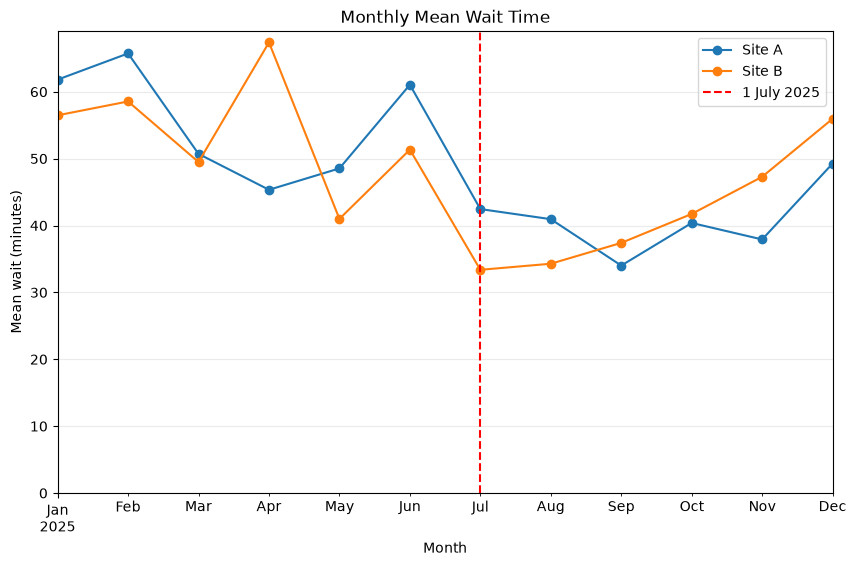

In [2]:
a_change = (v[(v.site=="Site A") & (v.period=="After")].wait_minutes.mean()
            - v[(v.site=="Site A") & (v.period=="Before")].wait_minutes.mean())
b_change = (v[(v.site=="Site B") & (v.period=="After")].wait_minutes.mean()
            - v[(v.site=="Site B") & (v.period=="Before")].wait_minutes.mean())
did = a_change - b_change
print("Site A change:", a_change)
print("Site B change:", b_change)
print("DiD:", did)

v["month"] = v["visit_date"].dt.to_period("M").dt.to_timestamp()
monthly = v.groupby(["month","site"])["wait_minutes"].agg(["mean","count"]).reset_index()
pivot = monthly.pivot(index="month", columns="site", values="mean")
pivot.plot(marker="o", figsize=(10,6), title="Monthly Mean Wait Time")
plt.axvline(pd.Timestamp("2025-07-01"), color="red", linestyle="--", label="1 July 2025")
plt.xlabel("Month"); plt.ylabel("Mean wait (minutes)")
plt.ylim(bottom=0); plt.legend(); plt.grid(alpha=.25); plt.show()


## Task 3: Department mix

period          After     Before    change
department                                
Cardiology  43.219608  52.527881 -9.308273
Emergency   60.341629  69.710317 -9.368689
Radiology   21.524123  30.213793 -8.689670
Raw change: -13.384069044800306
Mix-adjusted change: -9.127468550971713
Mix contribution: -4.256600493828593


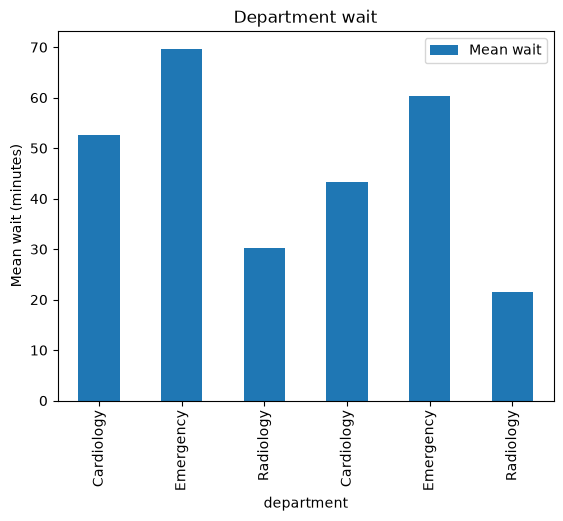

In [3]:
dept = v.groupby(["department","period"]).wait_minutes.mean().unstack("period")
dept["change"] = dept["After"] - dept["Before"]
print(dept)

before_weights = v[v.period=="Before"].department.value_counts(normalize=True)
after_weights = v[v.period=="After"].department.value_counts(normalize=True)
before_means = v[v.period=="Before"].groupby("department").wait_minutes.mean()
after_means = v[v.period=="After"].groupby("department").wait_minutes.mean()
pooled = pd.concat([before_weights, after_weights], axis=1).mean(axis=1)
mix_adjusted_change = (after_means*pooled).sum() - (before_means*pooled).sum()
raw_change = v[v.period=="After"].wait_minutes.mean() - v[v.period=="Before"].wait_minutes.mean()
print("Raw change:", raw_change)
print("Mix-adjusted change:", mix_adjusted_change)
print("Mix contribution:", raw_change-mix_adjusted_change)

dept.reset_index().melt(id_vars="department", value_vars=["Before","After"],
                       var_name="Period", value_name="Mean wait").pipe(
    lambda x: x.plot(kind="bar", x="department", y="Mean wait", title="Department wait")
)
plt.ylabel("Mean wait (minutes)")
plt.show()


## Tasks 4-7

In [4]:
short = v[v.wait_minutes<=90].satisfaction
long = v[v.wait_minutes>90].satisfaction
print("Satisfaction <=90:", short.mean(), "n:", short.count(), "missing%:", v[v.wait_minutes<=90].satisfaction.isna().mean()*100)
print("Satisfaction >90:", long.mean(), "n:", long.count(), "missing%:", v[v.wait_minutes>90].satisfaction.isna().mean()*100)
paired = v[["wait_minutes","satisfaction"]].dropna()
print("Wait/satisfaction correlation:", paired.corr().loc["wait_minutes","satisfaction"])

print("Overall mean/median/p90:", v.wait_minutes.mean(), v.wait_minutes.median(), v.wait_minutes.quantile(.90))
v["age_group"] = pd.cut(v.age, [-1,17,39,64,120], labels=["0-17","18-39","40-64","65+"])
print("Age groups:\n", v.groupby("age_group", observed=True).wait_minutes.agg(["mean","median","count"]))
print("Age/wait correlation:", v[["age","wait_minutes"]].corr().loc["age","wait_minutes"])
print("Triage waits:\n", v.groupby("triage_level").wait_minutes.agg(["mean","median","count"]))

q1, q3 = v.wait_minutes.quantile([.25,.75])
iqr = q3-q1
upper = q3+1.5*iqr
v["iqr_outlier"] = v.wait_minutes > upper
print("IQR outliers:", v.iqr_outlier.sum())
print("Department outlier counts:\n", v[v.iqr_outlier].department.value_counts())
print("Triage outlier counts:\n", v[v.iqr_outlier].triage_level.value_counts().sort_index())
print("Mean with/without outliers:", v.wait_minutes.mean(), v.loc[~v.iqr_outlier].wait_minutes.mean())
print("Skewness:", v.wait_minutes.skew(), "Longest:", v.wait_minutes.max(), "Over 180:", (v.wait_minutes>180).sum())


Satisfaction <=90: 3.6727362204724407 n: 2032 missing%: 0.0
Satisfaction >90: 2.277173913043478 n: 184 missing%: 0.0
Wait/satisfaction correlation: -0.33698491253361895
Overall mean/median/p90: 47.623194945848375 37.0 87.0
Age groups:
                 mean  median  count
age_group                          
0-17       50.591772    36.5    316
18-39      45.492711    37.5    686
40-64      46.733026    36.0    869
65+        51.382609    39.0    345
Age/wait correlation: -0.009045213924127382
Triage waits:
                    mean  median  count
triage_level                          
1              8.625000     8.0     96
2             28.133858    20.0    381
3             45.904656    38.0    902
4             58.623064    49.0    581
5             72.343750    56.5    256
IQR outliers: 83
Department outlier counts:
 department
Emergency     69
Cardiology    13
Radiology      1
Name: count, dtype: Int64
Triage outlier counts:
 triage_level
2     2
3    17
4    37
5    27
Name: count, d

## Task 8: Bootstrap DiD and adjustment

In [5]:
preA = v[(v.site=="Site A")&(v.period=="Before")].wait_minutes
postA = v[(v.site=="Site A")&(v.period=="After")].wait_minutes
preB = v[(v.site=="Site B")&(v.period=="Before")].wait_minutes
postB = v[(v.site=="Site B")&(v.period=="After")].wait_minutes
print("Site A Welch test:", stats.ttest_ind(postA, preA, equal_var=False, alternative="less"))
print("Site B Welch test:", stats.ttest_ind(postB, preB, equal_var=False, alternative="less"))

rng=np.random.default_rng(2025)
boots=[]
for _ in range(5000):
    a0=rng.choice(preA.to_numpy(), len(preA), replace=True).mean()
    a1=rng.choice(postA.to_numpy(), len(postA), replace=True).mean()
    b0=rng.choice(preB.to_numpy(), len(preB), replace=True).mean()
    b1=rng.choice(postB.to_numpy(), len(postB), replace=True).mean()
    boots.append((a1-a0)-(b1-b0))
print("Bootstrap 95% CI:", np.quantile(boots,[.025,.975]))

v["site_a"]=(v.site=="Site A").astype(int)
v["post"]=(v.period=="After").astype(int)
model=smf.ols("wait_minutes ~ site_a + post + site_a:post + C(department) + C(triage_level)", data=v).fit(cov_type="HC3")
print("Adjusted DiD:", model.params["site_a:post"])
print(v.groupby(["site","period"]).urgent.mean().mul(100))


Site A Welch test: TtestResult(statistic=np.float64(-3.705276415823928), pvalue=np.float64(0.0001105583814462212), df=np.float64(1159.5024712181878))
Site B Welch test: TtestResult(statistic=np.float64(-3.250136370294649), pvalue=np.float64(0.0006093626847448508), df=np.float64(593.8631079603323))


Bootstrap 95% CI: [-13.17798909   7.6879341 ]
Adjusted DiD: -2.750048426917994
site    period
Site A  After     22.187500
        Before    20.033113
Site B  After     20.272904
        Before    23.965142
Name: urgent, dtype: float64
